# Optimizing Pokémon Defensive Bulk  
### A Data‑Driven Exploration of HP vs Defense EV Allocation  
*By Evan Switzer*

---

In competitive Pokémon, small stat optimizations can decide entire matches.  
In this project, I built a model to determine the optimal distribution of HP and Defense EVs to minimize incoming damage.

This notebook walks through the logic, the math, and the visualization of the results.

## Setup
*(This section loads libraries and styling. You can collapse it when exporting.)*

In [80]:
import json
import math
import tkinter as tk
from tkinter import messagebox, ttk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D

import manim as mn
from manim import *

plt.style.use('style.mplstyle')

In [81]:
config.media_width = "75%"
config.verbosity = "WARNING"
config.background_color = BLUE_A
Text.set_default(color=BLACK, stroke_color=BLACK)
MathTex.set_default(color=BLACK, stroke_color=BLACK)

In [82]:
power = 80
atk = 150
base_health = 150
base_defense = 80
level = 50

defense_evs = 0
health_evs = 0
total_evs = 66

## Calculating Damage Percentages

To evaluate defensive bulk, I implemented the standard Pokémon damage formula with parameters for:
- HP EVs
- Defense EVs
- Base stats
- Multipliers (e.g., items, abilities)

The function below returns the percent of HP lost from a single hit.


In [83]:
%%manim -qm DamageFormula

class DamageFormula(Scene):
    def construct(self):
        formula = MathTex(r"damage = (\frac{(\frac{2 * Level}{5} + 2) * Power * \frac{Attack}{Defense}}{50} + 2) * Extras")
        self.play(Write(formula), run_time=3)
        self.wait()

Manim Community v0.20.1

In [84]:
def damage(defense_evs, base_defense=base_defense, def_mult=1, atk=150, power=100, level=50, bonus=[1]):
    calculated_defense = math.floor((base_defense + defense_evs + 20) * def_mult)

    raw_damage = math.floor((( ( (2 * level / 5) + 2) * power * ( (atk) / calculated_defense) ) / 50) + 2 )
    raw_damage_unrounded = (( ( (2 * level / 5) + 2) * power * ( (atk) / calculated_defense) ) / 50) + 2

    for b in bonus:
        raw_damage = round(raw_damage * b)
        raw_damage_unrounded = raw_damage_unrounded * b

    return raw_damage, raw_damage_unrounded

def damage_percent(defense_evs, health_evs, base_health=base_health, base_defense=base_defense, total_evs=total_evs, def_mult=1, atk=150, power=100, level=50, bonus=[1]):
    if (defense_evs + health_evs) > total_evs:  # Constraint check
        print("EV distribution exceeds total EV limit.")
        return None, None  # Invalid solution
    
    calculated_health = base_health + health_evs + 75
    raw_damage, raw_damage_unrounded = damage(defense_evs, base_defense, def_mult, atk, power, level, bonus)

    return raw_damage / calculated_health * 100, raw_damage

In [85]:
%%manim -qm TransformEquation

class TransformEquation(Scene):
    def construct(self):
        eq1 = MathTex(r"damage = (\frac{(\frac{2 * Level}{5} + 2) * Power * \frac{Attack}{Defense}}{50} + 2) * Extras")
        eq2 = MathTex(r"damage = (\frac{(\frac{2 * 50}{5} + 2) * Power * \frac{Attack}{Defense}}{50} + 2) * Extras")
        eq3 = MathTex(r"damage = (\frac{22 * Power * \frac{Attack}{Defense}}{50} + 2) * Extras")
        eq4 = MathTex(r"damage = (\frac{22}{50} * Power * \frac{Attack}{Defense} + 2) * Extras")
        eq5 = MathTex(r"damage = (0.44 * Power * \frac{Attack}{Defense} + 2) * Extras")
        simpEQ = MathTex(r"damage \propto \frac{Power}{2} * \frac{Attack}{Defense}")
        self.add(eq1)
        self.wait()
        self.play(TransformMatchingTex(eq1, eq2))
        self.wait()
        self.play(TransformMatchingTex(eq2, eq3))
        self.wait()
        self.play(TransformMatchingTex(eq3, eq4))
        self.wait()
        self.play(TransformMatchingTex(eq4, eq5))
        self.wait(2)
        self.play(TransformMatchingTex(eq5, simpEQ))
        self.wait()

Manim Community v0.20.1

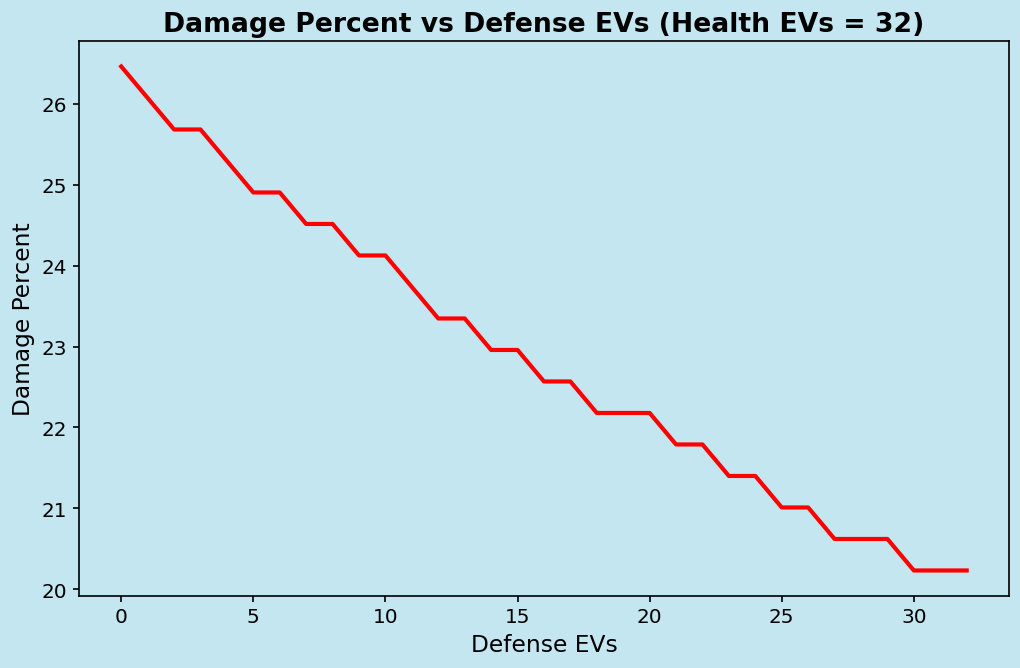

In [86]:
# Fix health_evs and vary defense_evs
health_evs = 32  # Example fixed value
defense_evs_range = range(0, 33)
damage_percent_values = [damage_percent(defense_evs, health_evs, base_health=base_health, base_defense=base_defense, total_evs=total_evs)[0] for defense_evs in defense_evs_range]

# Plot the curve
plt.plot(defense_evs_range, damage_percent_values, color='red')
plt.xlabel('Defense EVs')
plt.ylabel('Damage Percent')
plt.title(f'Damage Percent vs Defense EVs (Health EVs = {health_evs})')
plt.show()

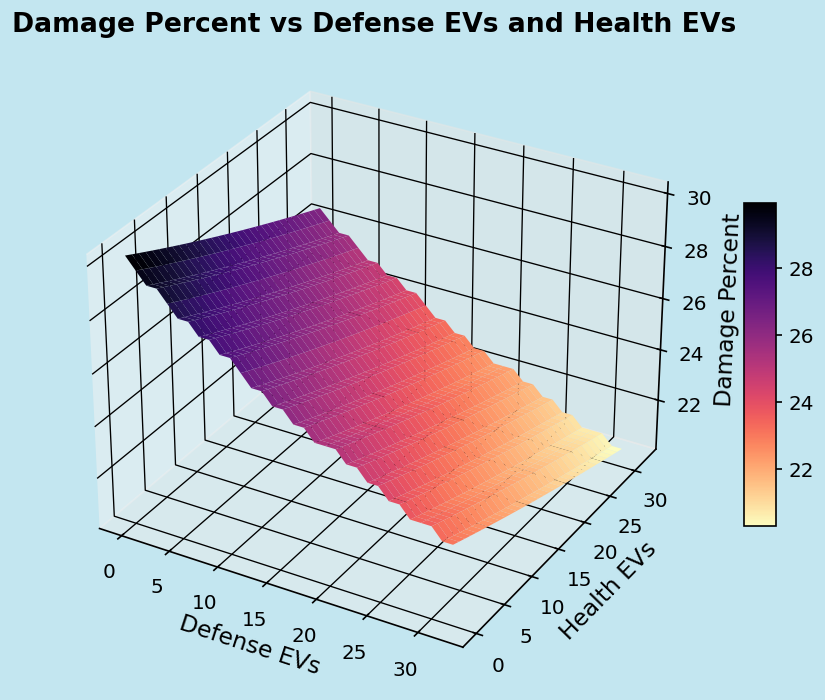

In [87]:
# Create a grid of defense_evs and health_evs
defense_evs_range = np.linspace(0, 32, 32)
health_evs_range = np.linspace(0, 32, 32)
defense_evs_grid, health_evs_grid = np.meshgrid(defense_evs_range, health_evs_range)

# Calculate damage_percent for each combination of defense_evs and health_evs
damage_percent_grid = np.zeros_like(defense_evs_grid)
for i in range(defense_evs_grid.shape[0]):
    for j in range(defense_evs_grid.shape[1]):
        defense_evs = defense_evs_grid[i, j]
        health_evs = health_evs_grid[i, j]
        if defense_evs + health_evs <= total_evs:  # Check total EV constraint
            damage_percent_grid[i, j], raw = damage_percent(defense_evs, health_evs, base_health=base_health, base_defense=base_defense, total_evs=total_evs)

# Plot the 3D surface
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(defense_evs_grid, health_evs_grid, damage_percent_grid, cmap='magma_r')

# Add labels and title
ax.set_xlabel('Defense EVs')
ax.set_ylabel('Health EVs')
ax.set_zlabel('Damage Percent')
ax.set_title('Damage Percent vs Defense EVs and Health EVs')

# Add a color bar
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)

plt.show()

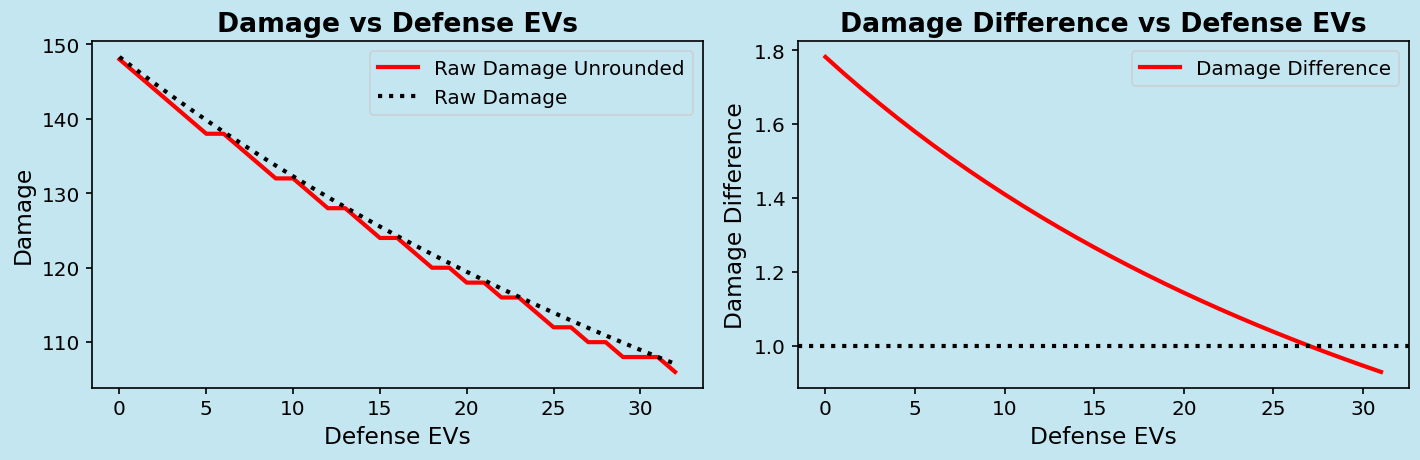

In [88]:
damage_numbers = []
for i in range(0, 33):
    damage_numbers.append(damage(defense_evs=i, base_defense=60, def_mult=1, atk=164, power=80, level=level, bonus=[2]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 

axes[0].plot(range(0, 33), [d[0] for d in damage_numbers], color='red', label='Raw Damage Unrounded')
axes[0].plot(range(0, 33), [d[1] for d in damage_numbers], color='black', linestyle=':', label='Raw Damage')
axes[0].set_xlabel('Defense EVs')
axes[0].set_ylabel('Damage')
axes[0].set_title(f'Damage vs Defense EVs')
axes[0].legend()

#calculate difference between raw damage from 1 point to the next
damage_diff = [damage_numbers[i][1] - damage_numbers[i+1][1]  for i in range(len(damage_numbers)-1)]

axes[1].plot(range(0, 32), damage_diff, color='red', label='Damage Difference')
axes[1].set_xlabel('Defense EVs')
axes[1].set_ylabel('Damage Difference')
axes[1].set_title(f'Damage Difference vs Defense EVs')
axes[1].legend()

axes[1].axhline(1, color='black', linestyle=':')  # Add a horizontal line at y=0 for reference

plt.tight_layout()
plt.show()

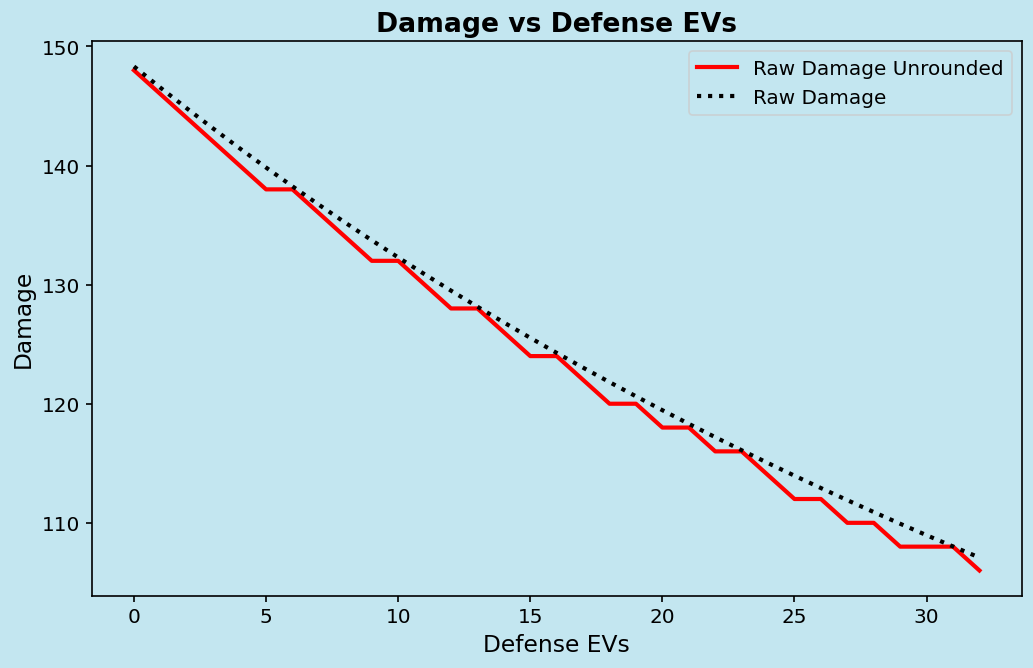

In [89]:
plt.plot(range(0, 33), [d[0] for d in damage_numbers], color='red', label='Raw Damage Unrounded')
plt.plot(range(0, 33), [d[1] for d in damage_numbers], color='black', linestyle=':', label='Raw Damage')
plt.xlabel('Defense EVs')
plt.ylabel('Damage')
plt.title(f'Damage vs Defense EVs')
plt.legend()

plt.show()

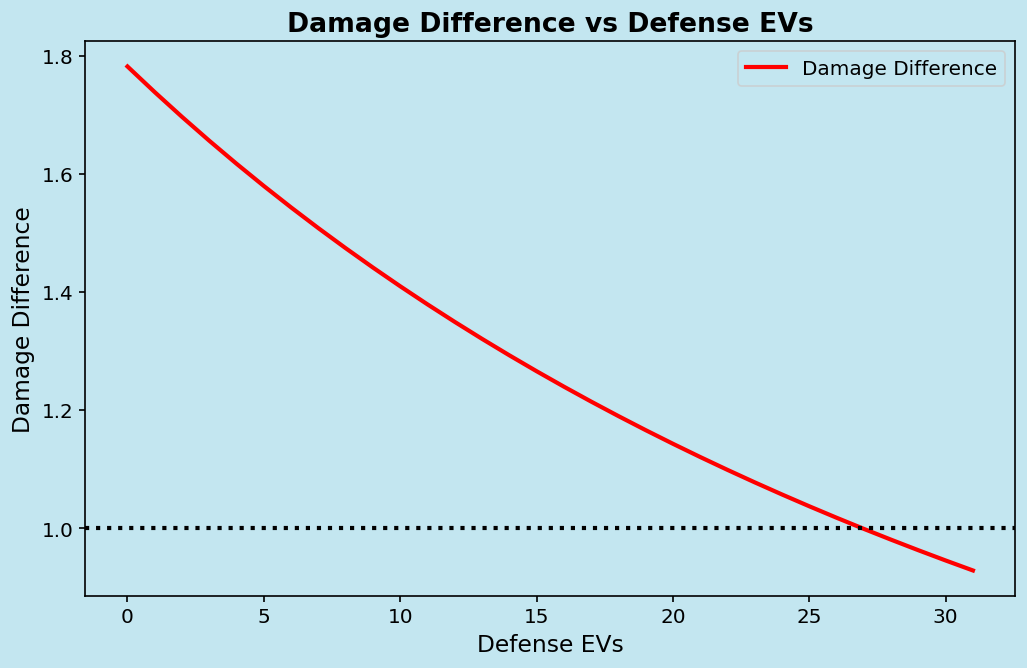

In [90]:
plt.plot(range(0, 32), damage_diff, color='red', label='Damage Difference')
plt.xlabel('Defense EVs')
plt.ylabel('Damage Difference')
plt.title(f'Damage Difference vs Defense EVs')
plt.axhline(1, color='black', linestyle=':')  # Add a horizontal line at y=0 for reference
plt.legend()

plt.show()

In [100]:
%%manim -qm DamageHeatmap

class DamageHeatmap(Scene):
    def construct(self):
        starting_base_health = 95
        starting_base_defense = 140
        total_evs = 40
        atk = 182
        power = 160
        level = 50
        bonus = 1.5
        def_mult = 1.0

        grid_size = 32
        cell_size = 0.35
        step = 1

        def damage_percent(defense_evs, health_evs):
            calculated_health = starting_base_health + health_evs + 75
            calculated_defense = math.floor((starting_base_defense + defense_evs + 20) * def_mult)
            if (defense_evs + health_evs) > total_evs:
                return 0
            return ((((2 * level / 5) + 2) * power * ((atk * bonus) / calculated_defense)) / 50 + 2) / calculated_health * 100

        values = [[damage_percent(j * step, i * step) for j in range(grid_size)] for i in range(grid_size)]
        valid = [v for row in values for v in row if v > 0]
        max_val = max(valid)
        min_val = min(valid)

        min_positions = []
        for i in range(grid_size):
            for j in range(grid_size):
                #print(f"Value at ({i}, {j}): {values[i][j]}")
                if values[i][j] == min_val:
                    min_positions.append((i, j))

        plot_axes = Axes(
            x_range=[0, grid_size, 4],
            y_range=[0, grid_size, 4],
            x_length=6.0,
            y_length=6.0,
            axis_config={
                "color": BLACK,
                "include_numbers": True,
                "font_size": 18,
                "label_direction": DOWN,
                "decimal_number_config": {"color": BLACK},
            },
            tips=False,
        )

        cells = VGroup()
        cell_lookup = {}
        grid_origin = plot_axes.c2p(0.5, 0.5)
        x_step = plot_axes.x_length / grid_size
        y_step = plot_axes.y_length / grid_size

        for i in range(grid_size):
            for j in range(grid_size):
                val = values[i][j]
                if val > 0:
                    t = (val - min_val) / (max_val - min_val) if max_val > min_val else 0.5
                    color = interpolate_color(RED_A, MAROON_E, t)
                    sq = Square(side_length=min(x_step, y_step), fill_color=color, fill_opacity=1, stroke_width=0.3)
                else:
                    sq = Square(side_length=min(x_step, y_step), fill_opacity=0, stroke_width=0)
                sq.move_to(grid_origin + np.array([j * x_step, i * y_step, 0]))
                cells.add(sq)
                cell_lookup[(i, j)] = sq

        title = Text("Damage % Heatmap", font_size=30)
        x_label = Text("Defense EVs", font_size=24)
        y_label = Text("HP EVs", font_size=24).rotate(PI / 2)

        title.next_to(plot_axes, UP, buff=0.35)
        x_label.next_to(plot_axes, DOWN, buff=0.35)
        y_label.next_to(plot_axes, LEFT, buff=0.45)

        layout = VGroup(plot_axes, cells, title, x_label, y_label)
        layout.scale_to_fit_width(config.frame_width * 0.9)
        layout.scale_to_fit_height(config.frame_height * 0.84)
        layout.move_to(ORIGIN)

        cells_sorted = sorted(cells, key=lambda cell: cell.get_center()[0] + cell.get_center()[1])

        #create colour scale legend
        legend = VGroup()
        for i in range(5):
            t = i / 4
            color = interpolate_color(RED_A, MAROON_E, t)
            rect = Rectangle(width=0.5, height=0.3, fill_color=color, fill_opacity=1, stroke_width=0.3)
            label = Text(f"{min_val + t * (max_val - min_val):.1f}%", font_size=14)
            label.next_to(rect, RIGHT, buff=0.1)
            legend.add(VGroup(rect, label))
        legend.arrange(DOWN, aligned_edge=LEFT)
        legend.next_to(plot_axes, RIGHT, buff=0.5)

        self.add(plot_axes, title, x_label, y_label, legend)
        self.play(LaggedStart(*[FadeIn(c) for c in cells_sorted], lag_ratio=0.01), run_time=3)

        markers = VGroup()
        labels = VGroup()
        #print(min_positions)
        for i, j in min_positions:
            cell = cell_lookup[(i, j)]
            markers.add(SurroundingRectangle(cell, color=BLACK, buff=0.02, stroke_width=3))
            labels.add(Text(f"{min_val:.1f}%", font_size=14, color=BLACK).next_to(cell, UP, buff=0.04))

        self.play(Create(markers), FadeIn(labels))
        self.wait(2)



Manim Community v0.20.1

In [92]:
# Find the minimum damage_percent and its coordinates
min_damage_percent = np.min(damage_percent_grid)
min_index = np.unravel_index(np.argmin(damage_percent_grid), damage_percent_grid.shape)
optimal_defense_evs = defense_evs_grid[min_index]
optimal_health_evs = health_evs_grid[min_index]

print(f"Minimum Damage Percent: {min_damage_percent}")
print(f"Optimal Defense EVs: {optimal_defense_evs}")
print(f"Optimal Health EVs: {optimal_health_evs}")

Minimum Damage Percent: 20.233463035019454
Optimal Defense EVs: 30.967741935483872
Optimal Health EVs: 32.0


In [93]:
%%manim -qm damageFormulas

class damageFormulas(Scene):
    def construct(self):
        # Define formulas, HP, Defense, Total Evs
        # draw 3 lines of text with the formulas for HP, Defense, and Total EVs
        eq1 = MathTex(r"HP = BaseHealth + x + 75").arrange(DOWN, aligned_edge=LEFT).to_edge(UP, buff=0.5)
        eq2 = MathTex(r"Defense = BaseDefense + y + 20").arrange(DOWN, aligned_edge=LEFT).next_to(eq1, DOWN, buff=0.5)
        eq3 = MathTex(r"TotalEVs = x + y").arrange(DOWN, aligned_edge=LEFT).next_to(eq2, DOWN, buff=0.5)

        self.play(Write(eq1))
        self.play(Write(eq2))
        self.play(Write(eq3))
        self.wait()


Manim Community v0.20.1

In [94]:
%%manim -qm bulkFormula

class bulkFormula(Scene):
    def construct(self):
        # Define the bulk formula
        eq1 = MathTex(r"Damage \propto \frac{Power}{2} * \frac{Attack}{Defense}").scale(0.8).to_edge(UP, buff=0.5)
        eq2 = MathTex(r"Damage \propto \frac{1}{Defense}").scale(0.8).next_to(eq1, DOWN, buff=0.5)
        eq3 = MathTex(r"Damage\% = \frac{Damage}{Health}").scale(0.8).next_to(eq2, DOWN, buff=0.5)

        eq4 = MathTex(r"Damage\% = \frac{\frac{1}{Defense}}{Health}").scale(0.8).next_to(eq3, DOWN, buff=0.5)
        eq5 = MathTex(r"Damage\% = \frac{1}{Defense * Health}").scale(0.8).next_to(eq4, DOWN, buff=0.5)

        #eq4 = MathTex(r"Bulk = \frac{1}{Damage}").next_to(eq3, DOWN, buff=0.5)



        self.play(Write(eq1))
        self.play(Write(eq2))
        self.play(Write(eq3))
        self.play(Write(eq4))
        self.play(Write(eq5))
        self.wait()
        self.play(FadeOut(eq1), FadeOut(eq2), FadeOut(eq3), FadeOut(eq4), FadeOut(eq5))

        bulk_eq1 = MathTex(r"Bulk = \frac{1}{Damage}").scale(0.8).to_edge(UP, buff=0.5)
        bulk_eq2 = MathTex(r"Bulk = Defense * Health").scale(1).next_to(bulk_eq1, DOWN, buff=0.5)


        self.play(Write(bulk_eq1))
        self.play(Write(bulk_eq2))
        self.wait()


Manim Community v0.20.1

In [101]:
def optimize_damage_percent(base_health, base_defense, total_evs, def_mult=1, atk=150, power=100, level=50):
    """
    Optimizes Damage Percent based on given constants and EV constraints.

    Args:
        power (int): Power of the move.
        atk (int): Attack stat.
        base_health (int): Base health stat.
        base_defense (int): Base defense stat.
        level (int): Level of the Pokémon.
        total_evs (int): Total EVs available to distribute.

    Returns:
        dict: A dictionary containing the optimal HP EVs, Defense EVs, maximum Damage Percent, and a plot.
    """

    # Generate all valid combinations of hp_evs and def_evs
    ev_combinations = [
        (hp, total_evs - hp)
        for hp in range(0, min(32, total_evs) + 1)
        if total_evs - hp <= 32
    ]

    # Calculate damage_percent for each combination
    results = []
    for hp, defense in ev_combinations:
        print(f"{defense}, {hp}, {base_health}, {base_defense}, {total_evs}, {def_mult}, {atk}, {power}, {level}")
        hp_percent, _ = damage_percent(defense, hp, base_health=base_health, base_defense=base_defense, total_evs=total_evs, def_mult=def_mult, atk=atk, power=power, level=level)
        results.append((hp, defense, hp_percent))
        75, 60, 50, 0.8, 150, 100, 50

    # Find the optimal combination
    optimal_combination = min(results, key=lambda x: x[2])  # Minimize damage_percent
    optimal_hp, optimal_defense, min_damage_percent = optimal_combination

    # Print the optimal results
    print(f"Optimal HP EVs: {optimal_hp}")
    print(f"Optimal Defense EVs: {optimal_defense}")
    print(f"Minimum Damage Percent: {min_damage_percent}")

    # Plot the results
    hp_evs = [r[0] for r in results]
    def_evs = [r[1] for r in results]
    damage_percents = [r[2] for r in results]

    plt.figure(figsize=(10, 6))
    plt.scatter(hp_evs, def_evs, c=damage_percents, cmap='autumn_r', s=100)
    plt.colorbar(label='Damage Percent')
    plt.xlabel('HP EVs')
    plt.ylabel('Defense EVs')
    plt.title('Damage Percent for Each EV Combination')
    plt.show()

    # Return the results as a dictionary
    return {
        "optimal_hp_evs": optimal_hp,
        "optimal_defense_evs": optimal_defense,
        "min_damage_percent": min_damage_percent
    }

# HP = Base + StatPoints + 75
# OtherStat = lower( (Base + StatPoints + 20) * Allignment(1.2/0.8/1) )

32, 18, 75, 60, 50, 0.8, 150, 100, 50
31, 19, 75, 60, 50, 0.8, 150, 100, 50
30, 20, 75, 60, 50, 0.8, 150, 100, 50
29, 21, 75, 60, 50, 0.8, 150, 100, 50
28, 22, 75, 60, 50, 0.8, 150, 100, 50
27, 23, 75, 60, 50, 0.8, 150, 100, 50
26, 24, 75, 60, 50, 0.8, 150, 100, 50
25, 25, 75, 60, 50, 0.8, 150, 100, 50
24, 26, 75, 60, 50, 0.8, 150, 100, 50
23, 27, 75, 60, 50, 0.8, 150, 100, 50
22, 28, 75, 60, 50, 0.8, 150, 100, 50
21, 29, 75, 60, 50, 0.8, 150, 100, 50
20, 30, 75, 60, 50, 0.8, 150, 100, 50
19, 31, 75, 60, 50, 0.8, 150, 100, 50
18, 32, 75, 60, 50, 0.8, 150, 100, 50
Optimal HP EVs: 21
Optimal Defense EVs: 29
Minimum Damage Percent: 45.02923976608187


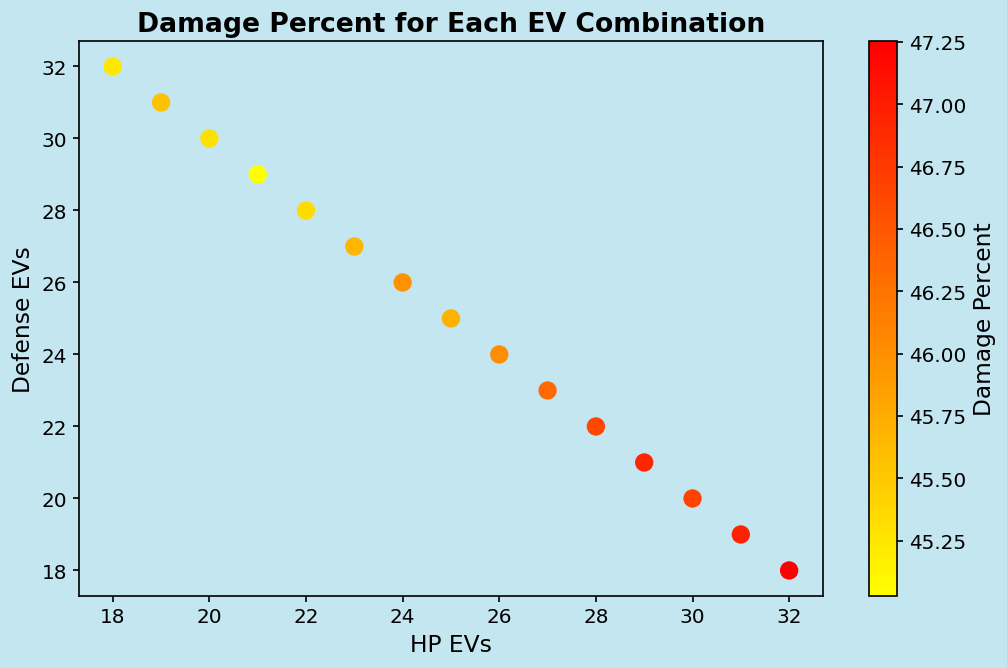

{'optimal_hp_evs': 21, 'optimal_defense_evs': 29, 'min_damage_percent': 45.02923976608187}


In [102]:
#simplified formula for Damage Percent:
#((( 22 / calculated_defense ) / 50) + 2 ) / (calculated_health) * 100

# Example usage
results = optimize_damage_percent(
    base_health=75,
    base_defense=60,
    total_evs=50,
    def_mult = 0.8
)

print(results)

In [ ]:
#Targets x Parental Bond x Weather x GlaiveRush x Critical x random x STAB x Type(Super Effective) x Burn x other x ZMove x TeraShield
#items like fairy feather are given straight to power
#most abilities are given straight to power too

attacks = [
   # {"name": "Power Gem", "power": 80, "atk": 182, "bonus": [1.5,2], "PhySpec": "Special", "evs": []},
    {"name": "Dire Claw", "power": 80, "atk": 182, "bonus": [1.5, 2], "PhySpec": "Physical", "evs": []},
    #{"name": "Iron Head", "power": 80, "atk": 205, "bonus": [1.5,2], "PhySpec": "Physical", "evs": []},
    #{"name": "Flash Cannon", "power": 80, "atk": 194, "bonus": [1.5,2], "PhySpec": "Special", "evs": []},
    #{"name": "Last Respects", "power": 50, "atk": 164, "bonus": [2,2], "PhySpec": "Physical", "evs": []},
    {"name": "Hyper Voice", "power": 90*1.2*1.2, "atk": 178, "bonus": [0.75, 1.5, 2], "PhySpec": "Special", "evs": []},
    #{"name": "Liquidation", "power": 85, "atk": 180, "bonus": [2], "PhySpec": "Physical", "evs": []},
]


#defense = {"name": "Aerodactyl", "base_health": 80, "base_defense": 65, "base_special_defense": 75}
#defense = {"name": "Mega Altaria", "base_health": 75, "base_defense": 110, "base_special_defense": 105}
defense = {"name": "Decidueye-Hisui", "base_health": 88, "base_defense": 80, "base_special_defense": 95}
#defense = {"name": "Gallade", "base_health": 68, "base_defense": 65, "base_special_defense": 115}


starting_base_health = defense['base_health']
starting_base_defense = defense['base_defense']
starting_base_special_defense = defense['base_special_defense']
level = 50

evs_map = np.zeros((33, 33))

attackN = 0
for a in attacks:
    print(f"Optimizing for {a['name']}...")
    for i, hp in enumerate(range(0, 33)):
        for j, defense in enumerate(range(0, 33)):
            base_defense = starting_base_defense if a['PhySpec'] == "Physical" else starting_base_special_defense
            evs_map[i, j], raw = damage_percent(defense_evs = defense, health_evs = hp, base_health = starting_base_health, base_defense = base_defense, total_evs = 50, def_mult = 1, atk = a['atk'], power = a['power'], level = level, bonus = a['bonus'])
            print(f"HP EVs: {hp}, Defense EVs: {defense}, Damage Percent: {evs_map[i, j]}, Raw Damage: {raw}")
            attacks[attackN]['evs'].append((hp, defense, evs_map[i, j]))

    attackN += 1


Optimizing for Dire Claw...
HP EVs: 0, Defense EVs: 0, Damage Percent: 121.47239263803682, Raw Damage: 198
HP EVs: 0, Defense EVs: 1, Damage Percent: 120.24539877300613, Raw Damage: 196
HP EVs: 0, Defense EVs: 2, Damage Percent: 117.79141104294479, Raw Damage: 192
HP EVs: 0, Defense EVs: 3, Damage Percent: 117.79141104294479, Raw Damage: 192
HP EVs: 0, Defense EVs: 4, Damage Percent: 115.33742331288343, Raw Damage: 188
HP EVs: 0, Defense EVs: 5, Damage Percent: 115.33742331288343, Raw Damage: 188
HP EVs: 0, Defense EVs: 6, Damage Percent: 114.11042944785277, Raw Damage: 186
HP EVs: 0, Defense EVs: 7, Damage Percent: 112.88343558282207, Raw Damage: 184
HP EVs: 0, Defense EVs: 8, Damage Percent: 112.88343558282207, Raw Damage: 184
HP EVs: 0, Defense EVs: 9, Damage Percent: 110.42944785276075, Raw Damage: 180
HP EVs: 0, Defense EVs: 10, Damage Percent: 110.42944785276075, Raw Damage: 180
HP EVs: 0, Defense EVs: 11, Damage Percent: 107.97546012269939, Raw Damage: 176
HP EVs: 0, Defense EVs

In [ ]:
#attach the lowest defense percent and lowest special defense percent to each unique hp evs value for each attack

#create dict with a evs key for 1-32
optimized_evs = {hp: {"defense": None, "special_defense": None} for hp in range(33)}

for a in attacks:
    print(a)
    #for each hp ev value get the lowest defense evs and lowest special defense evs and attach to optimized_evs dict
    for hp in range(33):
        #print(a['evs'])

                #gets ev1 and 2 for corrosponding hp
        pairs = [(ev[1], ev[2]) for ev in a['evs'] if ev[0] == hp and ev[2] is not None]
        if not pairs:
            continue

                    #gets evs and damage for all pairs where dmg < 100
        under_100 = [(d_ev, dmg) for d_ev, dmg in pairs if dmg < 100]
        #runs min on under_100 or pairs at [0]
        if under_100:
            min_defense_evs, chosen_damage = min(under_100, key=lambda x: x[0])
        else:
            min_defense_evs, chosen_damage = min(pairs, key=lambda x: x[0])

        if a['PhySpec'] == "Physical":
            if optimized_evs[hp]['defense'] is None or min_defense_evs > optimized_evs[hp]['defense']:
                optimized_evs[hp]['defense'] = min_defense_evs
                optimized_evs[hp]['defense_percent'] = chosen_damage
        else:
            if optimized_evs[hp]['special_defense'] is None or min_defense_evs > optimized_evs[hp]['special_defense']:
                optimized_evs[hp]['special_defense'] = min_defense_evs
                optimized_evs[hp]['special_defense_percent'] = chosen_damage


{'name': 'Dire Claw', 'power': 80, 'atk': 182, 'bonus': [1.5, 2], 'PhySpec': 'Physical', 'evs': [(0, 0, np.float64(121.47239263803682)), (0, 1, np.float64(120.24539877300613)), (0, 2, np.float64(117.79141104294479)), (0, 3, np.float64(117.79141104294479)), (0, 4, np.float64(115.33742331288343)), (0, 5, np.float64(115.33742331288343)), (0, 6, np.float64(114.11042944785277)), (0, 7, np.float64(112.88343558282207)), (0, 8, np.float64(112.88343558282207)), (0, 9, np.float64(110.42944785276075)), (0, 10, np.float64(110.42944785276075)), (0, 11, np.float64(107.97546012269939)), (0, 12, np.float64(107.97546012269939)), (0, 13, np.float64(106.74846625766872)), (0, 14, np.float64(106.74846625766872)), (0, 15, np.float64(105.52147239263803)), (0, 16, np.float64(105.52147239263803)), (0, 17, np.float64(103.06748466257669)), (0, 18, np.float64(103.06748466257669)), (0, 19, np.float64(100.61349693251533)), (0, 20, np.float64(100.61349693251533)), (0, 21, np.float64(99.38650306748467)), (0, 22, np.f

In [ ]:
#for each set of optimized evs find the one with the least evs total (hp, def, spD) and attach it to optimized evs
for hp in range(33):
        
    if (any(attack["PhySpec"] == "Physical" for attack in attacks) and optimized_evs[hp]['defense'] is None) or (any(attack["PhySpec"] == "Special" for attack in attacks) and optimized_evs[hp]['special_defense'] is None) or (any(attack["PhySpec"] == "Physical" for attack in attacks) and optimized_evs[hp]['defense_percent'] >= 100) or (any(attack["PhySpec"] == "Special" for attack in attacks) and optimized_evs[hp]['special_defense_percent'] >= 100):
        #remove key
        del optimized_evs[hp]
        continue
    defense_evs = 0 if optimized_evs[hp]['defense'] is None else optimized_evs[hp]['defense']
    special_defense_evs = 0 if optimized_evs[hp]['special_defense'] is None else optimized_evs[hp]['special_defense']
    total_evs = hp + defense_evs + special_defense_evs
    optimized_evs[hp]['total_evs'] = total_evs

In [ ]:
#print min total evs and corresponding hp, defense, and special defense evs
min_total_evs = min([optimized_evs[hp]['total_evs'] for hp in optimized_evs])
best_evs = None
for hp in optimized_evs:
    if optimized_evs[hp]['total_evs'] == min_total_evs:
        print(f"Optimal HP EVs: {hp}, Optimal Defense EVs: {optimized_evs[hp]['defense']}, Optimal Special Defense EVs: {optimized_evs[hp]['special_defense']}, Total EVs: {optimized_evs[hp]['total_evs']}")
        best_evs = optimized_evs[hp]

Optimal HP EVs: 30, Optimal Defense EVs: 2, Optimal Special Defense EVs: 5, Total EVs: 37


In [ ]:
best_evs['hp'] = best_evs['total_evs'] - (0 if best_evs['defense'] is None else best_evs['defense']) - (0 if best_evs['special_defense'] is None else best_evs['special_defense'])

print(f"HP: {best_evs['hp']}, Defense: {best_evs['defense']}, Special Defense: {best_evs['special_defense']}, Total EVs: {best_evs['total_evs']}")
for a in attacks:
    if a['PhySpec'] == "Physical":
        #get the matching hp and def (x, x, 0) tuple from a['evs'] where x is the hp evs and def evs from best_evs
        for ev in a['evs']:
            if ev[0] == best_evs['hp'] and ev[1] == best_evs['defense']:
                print(f"{a['name']} - {ev[2]:.2f}%")
    else:
        for ev in a['evs']:
            if ev[0] == best_evs['hp'] and ev[1] == best_evs['special_defense']:
                print(f"{a['name']} - {ev[2]:.2f}%")

HP: 30, Defense: 2, Special Defense: 5, Total EVs: 37
Dire Claw - 99.48%
Hyper Voice - 99.48%


## Results: Optimal EV Distribution

The plot below shows the damage taken across all valid HP/Defense EV combinations.

**Key finding:**  
> The optimal bulk occurs when allocating **all EVs to Defense**, given this stat profile.


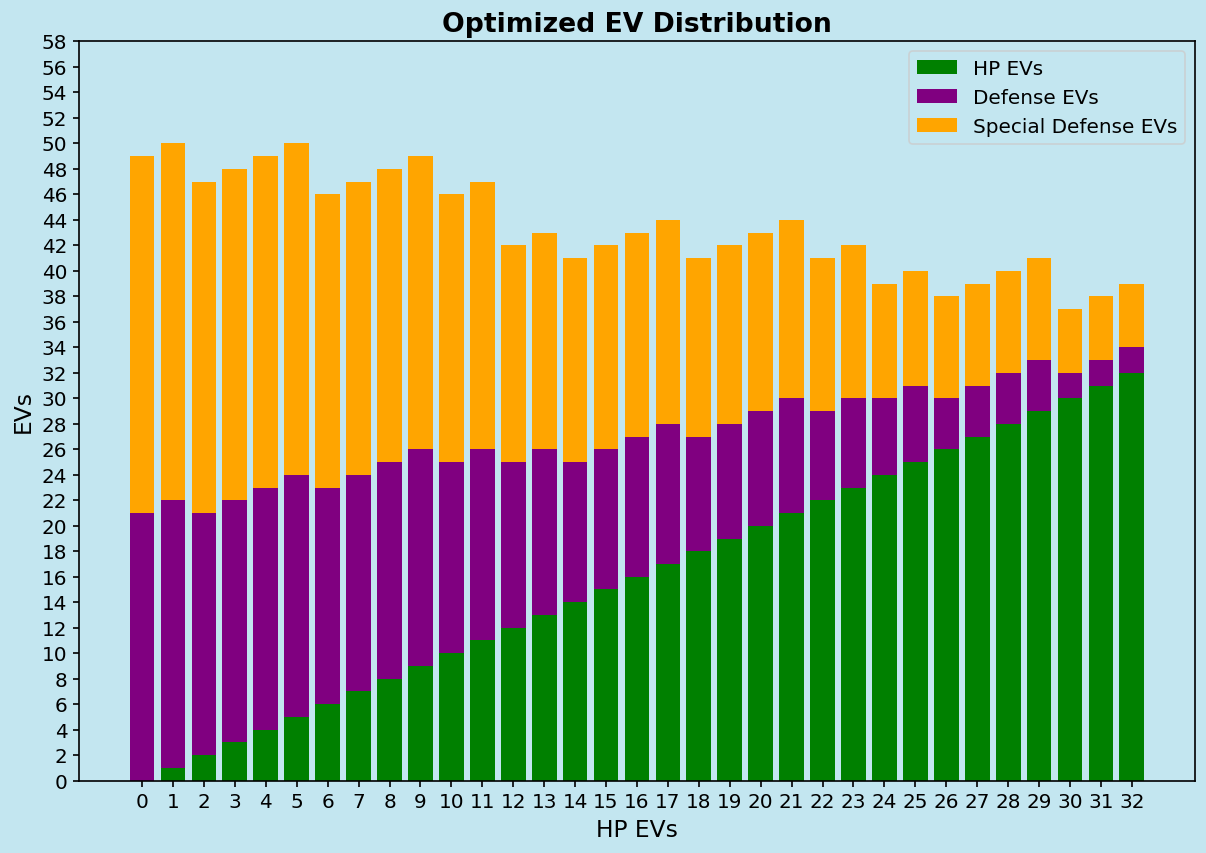

In [ ]:
#graph optimized_evs in a stacked bar chart with total evs on the y axis, with different colors for hp, defense and special defense evs
hp_evs = list(optimized_evs.keys())
defense_evs = [d or 0 for d in [optimized_evs[hp]['defense'] for hp in optimized_evs]]
special_defense_evs = [d or 0 for d in [optimized_evs[hp]['special_defense'] for hp in optimized_evs]]
total_evs = [optimized_evs[hp]['total_evs'] for hp in optimized_evs]

plt.figure(figsize=(12, 8))
plt.bar(hp_evs, hp_evs, color='green', label='HP EVs')
plt.bar(hp_evs, defense_evs, bottom=hp_evs, color='purple', label='Defense EVs')
plt.bar(hp_evs, special_defense_evs, bottom=np.add(hp_evs, defense_evs), color='orange', label='Special Defense EVs')
plt.xlabel('HP EVs')
plt.xticks(hp_evs)
plt.ylabel('EVs')
plt.yticks(list(range(0, max(total_evs)+9, 2)))
plt.title('Optimized EV Distribution')
plt.legend()
plt.show()



In [ ]:
%%manim -qm StackedEVBarChart

class StackedEVBarChart(Scene):
    def construct(self):
        
        # Extract data from optimized_evs
        hp_evs = list(optimized_evs.keys())
        defense_evs_list = [d or 0 for d in [optimized_evs[hp]['defense'] for hp in optimized_evs]]
        special_defense_evs_list = [d or 0 for d in [optimized_evs[hp]['special_defense'] for hp in optimized_evs]]
        total_evs_list = [hp + defense + special_defense for hp, defense, special_defense in zip(hp_evs, defense_evs_list, special_defense_evs_list)]
        
        max_total = max(total_evs_list)
        
        # Create axes
        ax = Axes(
            x_range=[0, max(hp_evs) + 2, 4],
            y_range=[0, max_total + 6, 5],
            x_length=10,
            y_length=5,
            axis_config={"include_numbers": True,
                        "include_ticks": True,
                        "color": BLACK,
                        "decimal_number_config": {
                            "color": BLACK,
                            "num_decimal_places": 0
                            },
                        "exclude_origin_tick": False,
                        },
            x_axis_config={
                "numbers_to_include": (0, 4, 8, 12, 16, 20, 24, 28, 32),
                },
            tips=False,
        )

        ax.x_axis.ticks.shift(RIGHT * 0.3)
        ax.x_axis.numbers.shift(RIGHT * 0.3)
        
        # Create title and labels
        title = Text("Optimized EV Distribution - Stacked Bars", font_size=28, font='Arial')
        x_label = Text("HP EVs", font_size=20).next_to(ax.x_axis, DOWN, buff=0.3)
        y_label = Text("Total EVs", font_size=20).next_to(ax.y_axis, LEFT, buff=0.3).rotate(PI/2)
        
        title.to_edge(UP, buff=0.3)
        
        # Create legend
        legend_items = VGroup(
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=GREEN, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("HP EVs", font_size=14, color=BLACK)),
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=PURPLE, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("Defense EVs", font_size=14, color=BLACK)),
            VGroup(Rectangle(width=0.2, height=0.2, fill_color=ORANGE, fill_opacity=1, stroke_color=BLACK, stroke_width=0.5), Text("Sp.Def EVs", font_size=14, color=BLACK)),
        )
        for item in legend_items:
            item.arrange(RIGHT, buff=0.15)
        legend_items.arrange(DOWN, buff=0.2, aligned_edge=LEFT)
        legend_items = VGroup(legend_items, Rectangle(width=1.8, height=1.2, fill_opacity=0, stroke_color=BLACK, stroke_width=1))

        legend_items.to_corner(UR, buff=0.3)
        
        # Calculate bar width in scene coordinates
        # Height scale factor: axis plot area height / max y value
        height_scale = ax.y_length / (max_total + 6)
        
        # Create stacked bars - separated by segment type
        hp_bars = VGroup()
        defense_bars = VGroup()
        sp_def_bars = VGroup()
        
        for i, hp in enumerate(hp_evs):
            x_pos = hp + 1
            hp_height = hp_evs[i]
            defense_height = defense_evs_list[i]
            sp_def_height = special_defense_evs_list[i]
            
            # HP bar (green)
            hp_bar_height = hp_height * height_scale
            hp_bar = Rectangle(
                width=0.2,
                height=hp_bar_height,
                fill_color=GREEN,
                fill_opacity=0.9,
                stroke_width=1,
                stroke_color=BLACK
            )
            hp_bar.move_to(ax.c2p(x_pos, hp_height/2))
            hp_bars.add(hp_bar)
            
            # Defense bar (blue)
            if defense_height > 0:
                defense_bar_height = defense_height * height_scale
                defense_bar = Rectangle(
                    width=0.2,
                    height=defense_bar_height,
                    fill_color=PURPLE,
                    fill_opacity=0.9,
                    stroke_width=1,
                    stroke_color=BLACK
                )
                defense_bar.move_to(ax.c2p(x_pos, hp_height + defense_height/2))
                defense_bars.add(defense_bar)
            
            # Special Defense bar (orange)
            if sp_def_height > 0:
                sp_def_bar_height = sp_def_height * height_scale
                sp_def_bar = Rectangle(
                    width=0.2,
                    height=sp_def_bar_height,
                    fill_color=ORANGE,
                    fill_opacity=0.9,
                    stroke_width=1,
                    stroke_color=BLACK
                )
                sp_def_bar.move_to(ax.c2p(x_pos, hp_height + defense_height + sp_def_height/2))
                sp_def_bars.add(sp_def_bar)
        
        # Add axes and labels
        self.add(ax, title, x_label, y_label, legend_items)
        
        # # Animate bars growing column by column: for each HP value, grow HP -> Defense -> Sp.Def sequentially
        # animations = []
        # for i in range(len(hp_evs)):
        #     if i < len(hp_bars):
        #         animations.append(GrowFromEdge(hp_bars[i], DOWN))
        #     if i < len(defense_bars):
        #         animations.append(GrowFromEdge(defense_bars[i], DOWN))
        #     if i < len(sp_def_bars):
        #         animations.append(GrowFromEdge(sp_def_bars[i], DOWN))

        # self.play(LaggedStart(*animations, lag_ratio=0.02), run_time=2)

        for i in range(len(hp_evs)):
            # Grow HP bar
            if i < len(hp_bars):
                self.play(GrowFromEdge(hp_bars[i], DOWN), run_time=0.05)
            # Then grow Defense bar
            if i < len(defense_bars):
                self.play(GrowFromEdge(defense_bars[i], DOWN), run_time=0.05)
            # Then grow Sp.Def bar
            if i < len(sp_def_bars):
                self.play(GrowFromEdge(sp_def_bars[i], DOWN), run_time=0.05)
        
        self.wait(2)

Manim Community v0.20.1

## Key Takeaways

- Small EV changes can meaningfully shift survivability.
- For this statline, Defense investment outperforms HP investment.
- This method can generalize to any Pokémon or matchup.



## Conclusion

This project demonstrates how data modeling can reveal optimal strategies in competitive environments.  
By translating game mechanics into code, we can make informed, quantitative decisions about team building.

If you'd like the full notebook or want to see more analyses like this, feel free to reach out.
